# Load, inspect, and understand the dataset

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [106]:
df = pd.read_csv('Titanic-Dataset.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [107]:
df.shape

(891, 12)

In [108]:
df['Age'].unique()

array([22.  , 38.  , 26.  , 35.  ,   nan, 54.  ,  2.  , 27.  , 14.  ,
        4.  , 58.  , 20.  , 39.  , 55.  , 31.  , 34.  , 15.  , 28.  ,
        8.  , 19.  , 40.  , 66.  , 42.  , 21.  , 18.  ,  3.  ,  7.  ,
       49.  , 29.  , 65.  , 28.5 ,  5.  , 11.  , 45.  , 17.  , 32.  ,
       16.  , 25.  ,  0.83, 30.  , 33.  , 23.  , 24.  , 46.  , 59.  ,
       71.  , 37.  , 47.  , 14.5 , 70.5 , 32.5 , 12.  ,  9.  , 36.5 ,
       51.  , 55.5 , 40.5 , 44.  ,  1.  , 61.  , 56.  , 50.  , 36.  ,
       45.5 , 20.5 , 62.  , 41.  , 52.  , 63.  , 23.5 ,  0.92, 43.  ,
       60.  , 10.  , 64.  , 13.  , 48.  ,  0.75, 53.  , 57.  , 80.  ,
       70.  , 24.5 ,  6.  ,  0.67, 30.5 ,  0.42, 34.5 , 74.  ])

In [109]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [110]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [111]:
df.duplicated().sum()

np.int64(0)

In [112]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [113]:
df['Survived'].unique()
df['Survived'].value_counts()

,count
Survived,
0,549
1,342


# Exploratory Data Analysis (EDA)

<Axes: xlabel='Survived', ylabel='count'>

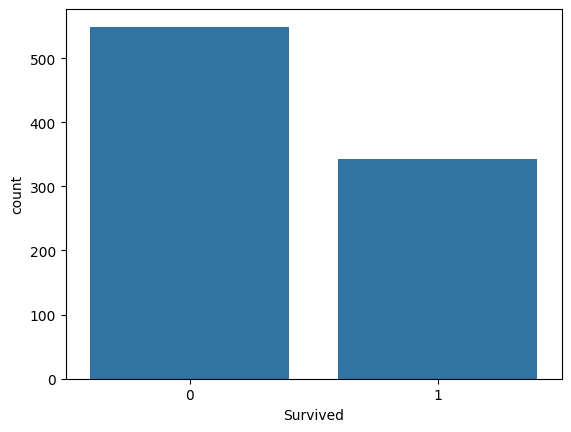

In [114]:
sns.countplot(x=df['Survived'])

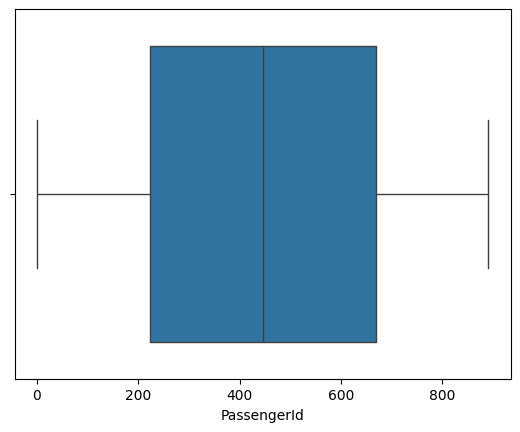

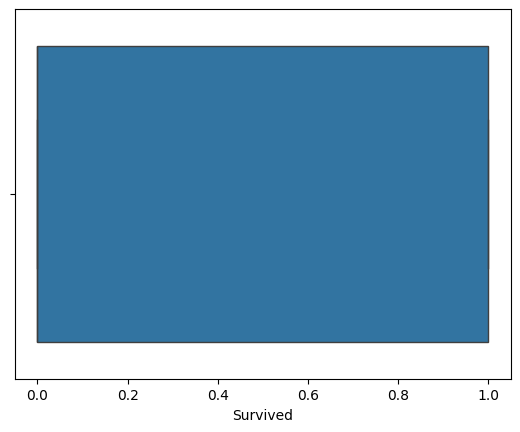

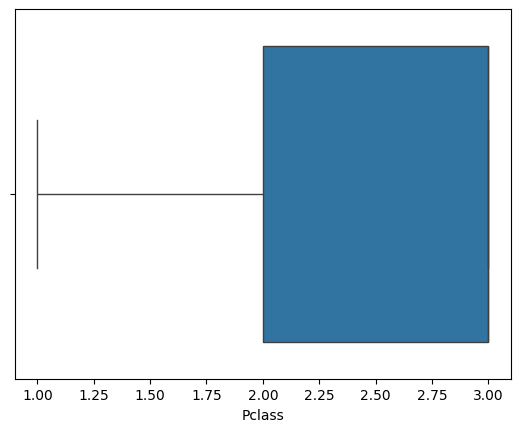

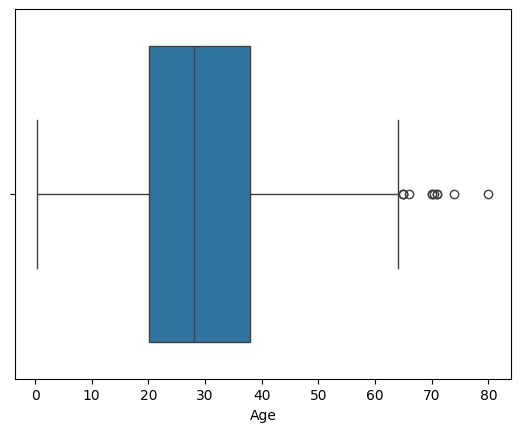

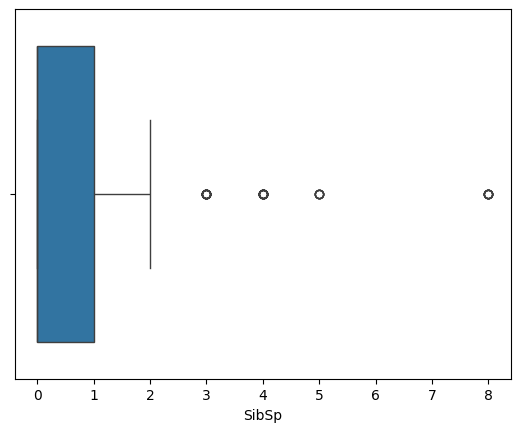

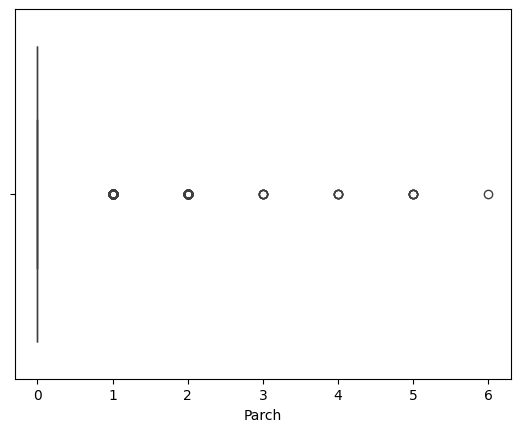

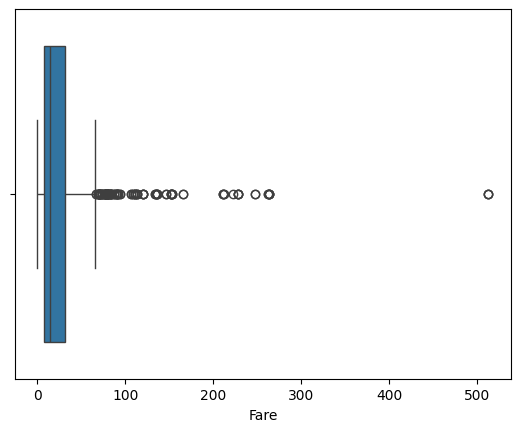

In [115]:
numerical_cols = df.select_dtypes(include='number').columns
for col in numerical_cols:
  sns.boxplot(x=df[col])
  plt.show()

<Axes: >

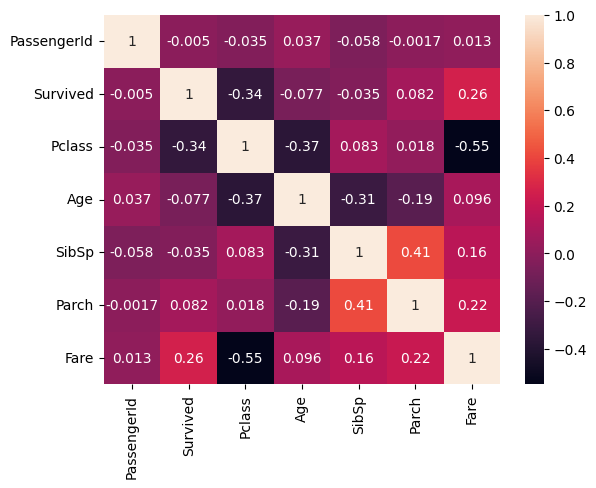

In [116]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

#Data Validation & Outlier Handling

In [117]:
df_copy = df.copy()
def remove_outliers_iqr(df, col, k=1.5):
    q1, q3 = df_copy[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return df_copy[(df_copy[col] >= lower) & (df_copy[col] <= upper)]
df_copy = remove_outliers_iqr(df_copy, "Fare")
df_copy = remove_outliers_iqr(df_copy, "Age")
df_copy = remove_outliers_iqr(df_copy, "Parch")
df_copy = remove_outliers_iqr(df_copy, "SibSp")

#Features, Target & Train-Test Split

In [118]:
from sklearn.model_selection import train_test_split
X=df_copy.drop(columns=["PassengerId", "Name", "Ticket", "Cabin",'Survived'])
y= df_copy['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42,stratify=y)

In [119]:
numerical_col = ['Pclass', 'SibSp', 'Age', 'Parch', 'Fare']
catagorical_col = ['Sex', 'Embarked']

#Handle Class Imbalance

In [120]:
neg,pos=np.bincount(y_train)
neg,pos

(np.int64(233), np.int64(138))

In [121]:
scale_weigths = neg/pos
scale_weigths

np.float64(1.6884057971014492)

#Preprocessing for Logistic Regression

In [122]:

#logistic Regressuon : impute + Scale numberic, imputer + one-not-encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
preprocesser_lr = ColumnTransformer(
    transformers=[
        #pipeline for numerical cols
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('scaler',StandardScaler())
        ]),numerical_col),
        #Pipeline fro the categorical cols
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy="constant",fill_value='missing')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),catagorical_col)
    ])


#Preprocessing for XGBoost

In [123]:
#XGBoost: Impute numeric only (No Scaling), impute + One - Hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numerical_col),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), catagorical_col)
    ])

#Preprocessing for Randomforestclassifier

In [124]:
preprocesser_rf = ColumnTransformer(
    transformers=[
    ("num", Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
]), numerical_col),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), catagorical_col),
])

#Preprocessing for Adaboost

In [125]:
preprocesser_Ad = ColumnTransformer(
    transformers=[
    ("num", Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
]), numerical_col),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), catagorical_col),
])

#Evaluation Helper Function

In [126]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,precision_recall_curve
def evaluate_model(model_name,model,X_test,y_test,threshold=0):
  y_pred_prob = model.predict_proba(X_test)[:,1]
  if threshold:
    y_pred = (y_pred_prob>threshold).astype(int)
  else:
    y_pred = model.predict(X_test)
   #Metrics
  accuracy     = accuracy_score(y_test, y_pred)    #Overall model's preformance
  precision    = precision_score(y_test, y_pred)   #When the model says 1, how oftenly is it actually 1.
  recall       = recall_score(y_test, y_pred)      #of the actual 1 how many did the model catches
  f1           = f1_score(y_test, y_pred)          #Harmonic mean of precision and recall

  conf_matrix   = confusion_matrix(y_test, y_pred)
  class_report  = classification_report(y_test, y_pred)

  print(f"{model_name} Metrics:")
  if threshold is not None: # Only print threshold if provided
    print(f"Used Threshold : {threshold:.2f}")
  print(f"Accuracy : {accuracy:.2f}")
  print(f"Precision : {precision:.2f}")
  print(f"Recall : {recall:.2f}")
  print(f"F1 : {f1:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)


  #Plotting confusion matrix
  sns.heatmap(conf_matrix, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()


  #Plotting ROC-AUC curve
  precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

#Stratified Cross-Validation

In [127]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}


In [128]:
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocesser_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [129]:
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight=scale_weigths,random_state=42
    ))
])

In [130]:
from sklearn.ensemble import RandomForestClassifier
rf_cv_pipeline = Pipeline([
    ('preprocessor', preprocesser_rf),
    ('classifier', RandomForestClassifier(
        n_estimators=300, max_depth=5,
        class_weight="balanced",random_state=42
    ))
])

In [131]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
ad_cv_pipeline = Pipeline([
    ('preprocessor', preprocesser_Ad),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, class_weight="balanced"),
        n_estimators=300,learning_rate=0.1,random_state=42
    ))
])

In [132]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline), ('Random Forest', rf_cv_pipeline), ('Adabost', ad_cv_pipeline)]:

                      cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

                      print(cv_name)
                      print(f"ROC-AUC : {cv_results['test_roc_auc'].mean():.4f}")
                      print(f"Accuracy : {cv_results['test_accuracy'].mean():.4f}")
                      print(f"Precision : {cv_results['test_precision'].mean():.4f}")
                      print(f"Recall : {cv_results['test_recall'].mean():.4f}")
                      print(f"F1 : {cv_results['test_f1'].mean():.4f}")
                      print()

Logistic Regression
ROC-AUC : 0.8211
Accuracy : 0.7737
Precision : 0.6811
Recall : 0.7458
F1 : 0.7106

XGBoost
ROC-AUC : 0.8154
Accuracy : 0.7817
Precision : 0.7176
Recall : 0.6955
F1 : 0.7039

Random Forest
ROC-AUC : 0.8474
Accuracy : 0.7845
Precision : 0.7244
Recall : 0.6952
F1 : 0.7060

Adabost
ROC-AUC : 0.7761
Accuracy : 0.7764
Precision : 0.7328
Recall : 0.6302
F1 : 0.6770



#Baseline Model — Logistic Regression

In [137]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocesser_lr),
    ('classifier', LogisticRegression(class_weight="balanced"))
])
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Pclass', 'SibSp', 'Age',
                                                   'Parch', 'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'Embarked'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Baseline Logistic Model Metrics:
Used Threshold : 0.00
Accuracy : 0.80
Precision : 0.71
Recall : 0.81
F1 : 0.75

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.80      0.84       116
           1       0.71      0.81      0.75        68

    accuracy                           0.80       184
   macro avg       0.79      0.81      0.80       184
weighted avg       0.81      0.80      0.81       184



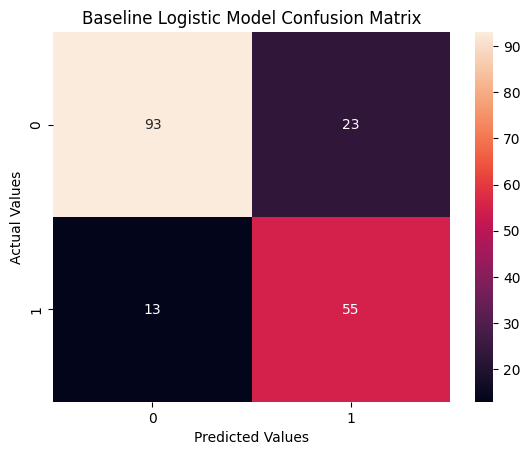

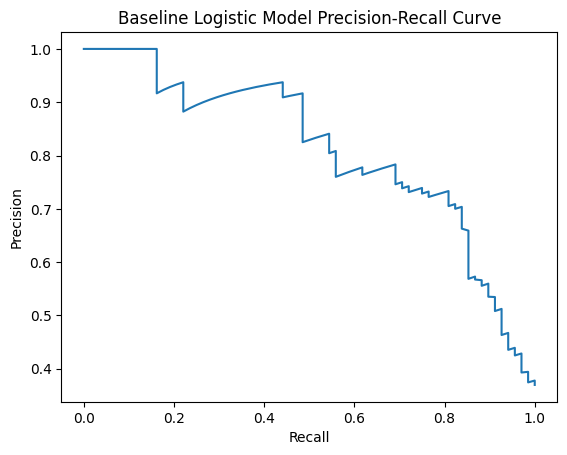

In [138]:
evaluate_model("Baseline Logistic Model", baseline_model ,X_test, y_test)

#Randomforest

In [139]:
from sklearn.pipeline import Pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocesser_rf),
    ('classifier', RandomForestClassifier(n_estimators=300, class_weight="balanced",
        random_state=42, n_jobs=-1))
])
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Pclass', 'SibSp', 'Age',
                                                   'Parch', 'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'Embarked'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

Random Forest Model Metrics:
Used Threshold : 0.00
Accuracy : 0.78
Precision : 0.71
Recall : 0.71
F1 : 0.71

Random Forest Model Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       116
           1       0.71      0.71      0.71        68

    accuracy                           0.78       184
   macro avg       0.77      0.77      0.77       184
weighted avg       0.78      0.78      0.78       184



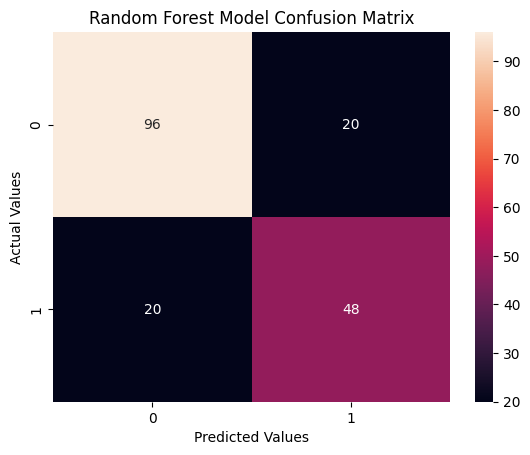

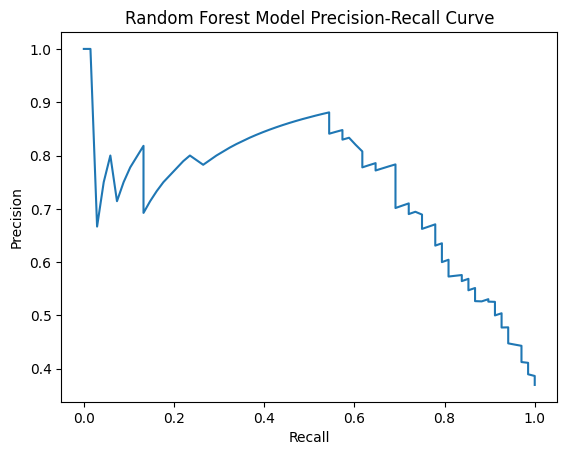

In [140]:
evaluate_model("Random Forest Model", rf_pipeline ,X_test, y_test)

#Adaboost

In [141]:
Ad_pipeline = Pipeline([
    ('preprocessor', preprocesser_Ad),
    ('classifier', AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, class_weight="balanced"),
        n_estimators=200,
        learning_rate=0.5,
        random_state=42,))
])
Ad_pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Pclass', 'SibSp', 'Age',
                                                   'Parch', 'Fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'Embarked'])])),
                ('classifier',
                 AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                                     max_depth=1),
                                    learning_rate=0.5, n_estimators=200,
                                    random_state=42))])

Ada boost Model Metrics:
Used Threshold : 0.00
Accuracy : 0.78
Precision : 0.75
Recall : 0.62
F1 : 0.68

Ada boost Model Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.88      0.84       116
           1       0.75      0.62      0.68        68

    accuracy                           0.78       184
   macro avg       0.77      0.75      0.76       184
weighted avg       0.78      0.78      0.78       184



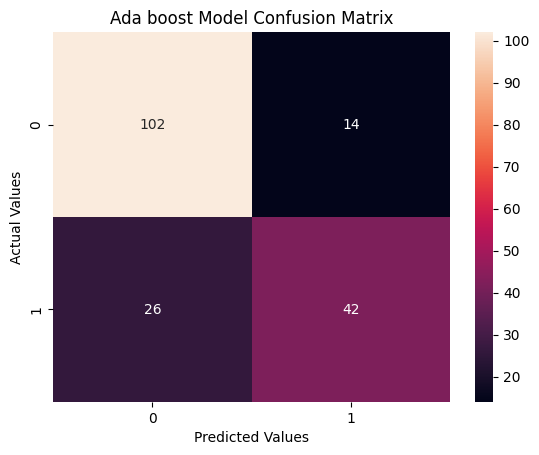

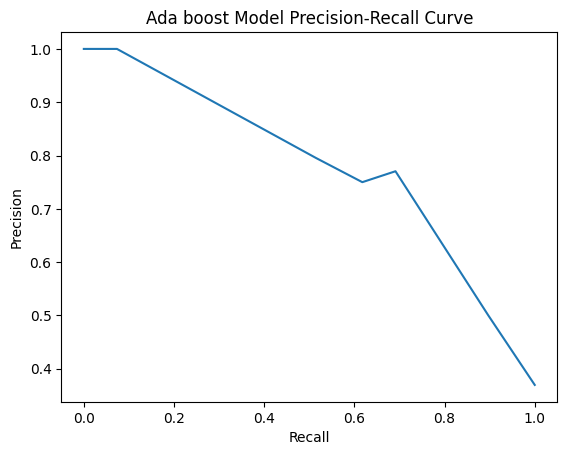

In [142]:
evaluate_model("Ada boost Model", Ad_pipeline ,X_test, y_test)

### Hyperparameter Tuning for Random Forest Classifier
We will use `GridSearchCV` to explore a parameter grid for our Random Forest pipeline. We will optimize for `roc_auc` because it is a balanced metric that measures classification strength, and then evaluate the final tuned model on our test set.

In [143]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid (using classifier__ prefix to target the pipeline's estimator)
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [3, 5, 8, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__class_weight': ['balanced', 'balanced_subsample', None]
}

# Create the GridSearchCV object
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Fit the grid search on the training data
print("Starting Hyperparameter Tuning for Random Forest...")
rf_grid_search.fit(X_train, y_train)

print("Best Parameters Found:")
print(rf_grid_search.best_params_)
print(f"Best Cross-Validated ROC-AUC: {rf_grid_search.best_score_:.4f}")

Starting Hyperparameter Tuning for Random Forest...
Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Best Parameters Found:
{'classifier__class_weight': 'balanced_subsample', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}
Best Cross-Validated ROC-AUC: 0.8598


Tuned Random Forest Model Metrics:
Used Threshold : 0.00
Accuracy : 0.82
Precision : 0.75
Recall : 0.78
F1 : 0.76

Tuned Random Forest Model Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.84      0.86       116
           1       0.75      0.78      0.76        68

    accuracy                           0.82       184
   macro avg       0.81      0.81      0.81       184
weighted avg       0.82      0.82      0.82       184



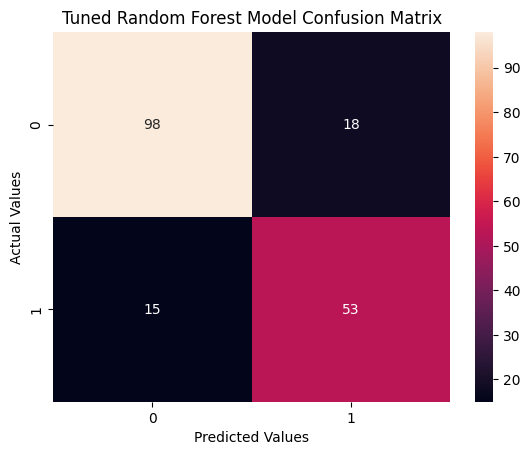

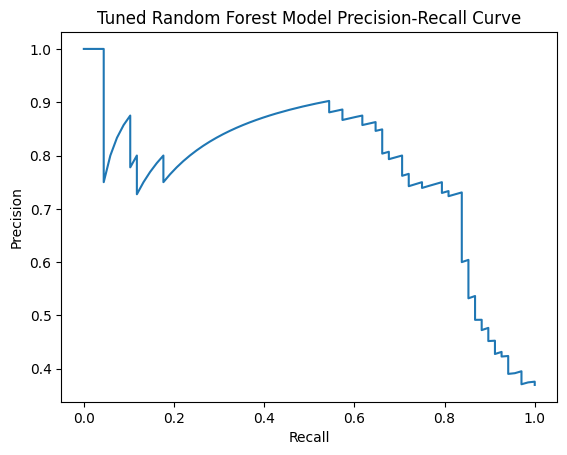

In [144]:
# Evaluate the best estimator on the test dataset
best_rf_model = rf_grid_search.best_estimator_
evaluate_model("Tuned Random Forest Model", best_rf_model, X_test, y_test)

Optimizing the Classification Threshold

randomforest Metrics:
Used Threshold : 0.98
Accuracy : 0.63
Precision : 0.00
Recall : 0.00
F1 : 0.00

randomforest Classification Report:
              precision    recall  f1-score   support

           0       0.63      1.00      0.77       116
           1       0.00      0.00      0.00        68

    accuracy                           0.63       184
   macro avg       0.32      0.50      0.39       184
weighted avg       0.40      0.63      0.49       184



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

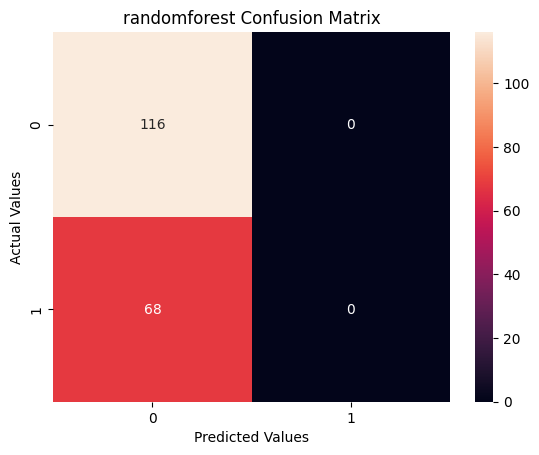

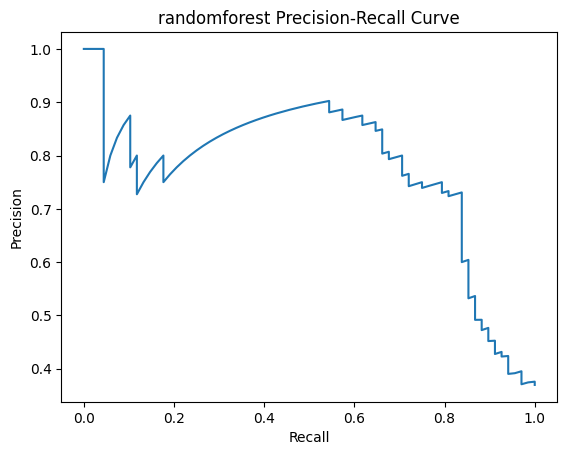

In [145]:
#Get the prob. of class 1 from XGBoost
prob = best_rf_model.predict_proba(X_test)[:, 1]

#For each threshold calculate Precision and Recall
precisions, recalls , thresholds = precision_recall_curve(y_test, prob)


#Calculate F1 score for each threshold
f1 = 2 * (precisions-recalls) / (precisions + recalls + 1e-9)

#Get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

#Evaluate the XGBoost model using that threshold.
evaluate_model("randomforest", best_rf_model, X_test, y_test, best_threshold)


#Probability Calibration

In [147]:

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = best_rf_model
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['Pclass',
                                                                                    'SibSp',
                                                                                    'Age',
                                                                                    'Parch',
                                                                                    'Fare']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                                   ('onehot',
                                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                                   ['Sex',
                                                                                    'Embarked'])])),
                                                 ('classifier',
                                                  RandomForestClassifier(class_weight='balanced_subsample',
                                                                         max_depth=8,
                                                                         min_samples_split=10,
                                                                         n_estimators=200,
                                                                         n_jobs=-1,
                                                                         random_state=42))]))

In [148]:
uncalibrated = best_rf_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

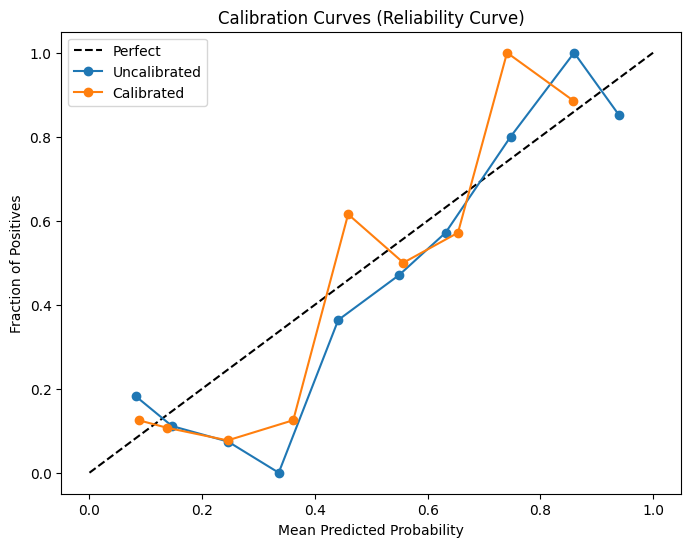

In [150]:
# Calculate calibration curve for both models
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)
actual_cal, predicted_cal = calibration_curve(y_test, calibrated, n_bins=10)

# Plot calibration curves side-by-side
plt.figure(figsize=(8, 6))
plt.plot([0,1], [0,1], 'k--', label="Perfect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label = "Uncalibrated"
)
plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "Calibrated"
)
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curves (Reliability Curve)")
plt.legend()
plt.show()

#SHAP Interpretation — Global & Local

In [152]:
import shap
xgb_classifier = best_rf_model.named_steps['classifier']

In [153]:
X_test_transformed = best_rf_model.named_steps['preprocessor'].transform(X_test)

In [154]:
feature_names = best_rf_model.named_steps['preprocessor'].get_feature_names_out()

In [155]:
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [156]:
explainer = shap.TreeExplainer(xgb_classifier)

In [157]:
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[[-0.11391026,  0.11391026],
        [-0.00761938,  0.00761938],
        [-0.00963794,  0.00963794],
        ...,
        [ 0.00879391, -0.00879391],
        [-0.00187334,  0.00187334],
        [ 0.00303029, -0.00303029]],

       [[ 0.04834737, -0.04834737],
        [-0.0078161 ,  0.0078161 ],
        [ 0.08675722, -0.08675722],
        ...,
        [ 0.02279624, -0.02279624],
        [-0.00185868,  0.00185868],
        [ 0.01111861, -0.01111861]],

       [[ 0.10117249, -0.10117249],
        [ 0.04605164, -0.04605164],
        [-0.02770369,  0.02770369],
        ...,
        [-0.05824495,  0.05824495],
        [-0.00314311,  0.00314311],
        [-0.02314641,  0.02314641]],

       ...,

       [[ 0.0899243 , -0.0899243 ],
        [-0.01343865,  0.01343865],
        [ 0.0296449 , -0.0296449 ],
        ...,
        [ 0.01830477, -0.01830477],
        [ 0.08167332, -0.08167332],
        [ 0.00216234, -0.00216234]],

       [[ 0.03843577, -0.03843577],
        [-0.01024655,  0.01

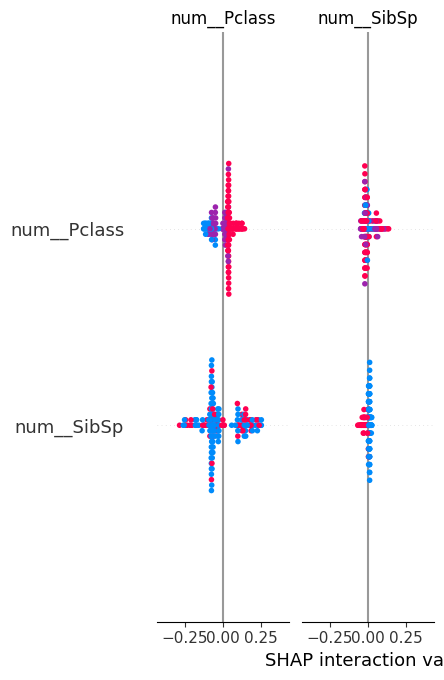

In [158]:
shap.summary_plot(shap_values, X_test_df)

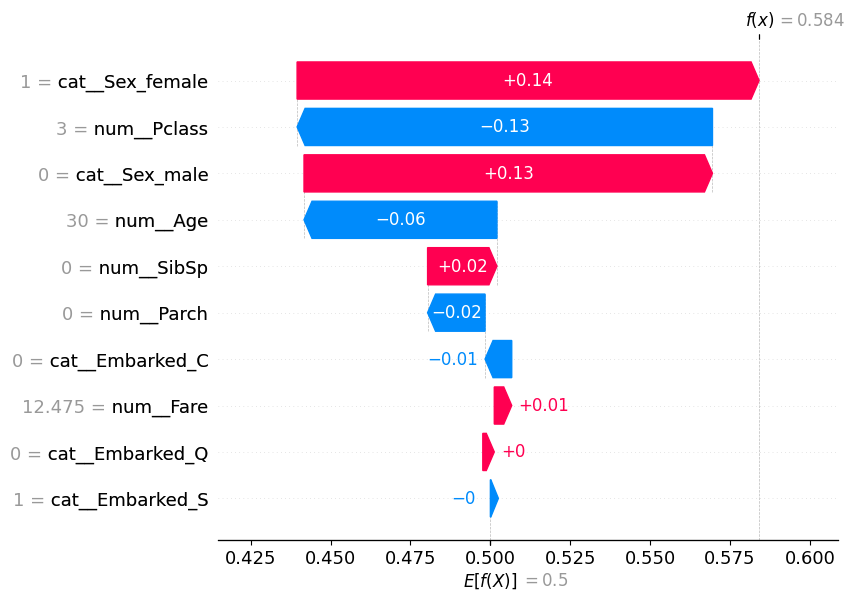

In [163]:
row_index = 5
# Select SHAP values for the positive class (class 1, index 1)
# shap_values shape is (n_samples, n_features, n_classes)
class_1_shap_values = shap_values[row_index, :, 1]

# Also retrieve the expected value for class 1
expected_value_class_1 = explainer.expected_value[1]

shap.plots.waterfall(
    shap.Explanation(
        values = class_1_shap_values,
        base_values = expected_value_class_1,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

In [165]:
y_pred = best_rf_model.predict(X_test)

In [166]:
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [167]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual']== 0) & (result_df['predicted']== 1)]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]

In [168]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")

False Positive : 18
False Negative : 15


In [169]:
import joblib

joblib.dump(calibrated_model, "Titanic.pkl")

['Titanic.pkl']

In [170]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']

### 📋 Machine Learning Pipeline Code Flow Summary

1. **Data Loading & Inspection (`wuIoEV8pxv2W` - `CFeztCO50aYx`)**:
   * Loaded the `Titanic-Dataset.csv` using pandas.
   * Inspected missing values (`Age`, `Cabin`, `Embarked`), dataset shape, and overall summary statistics.

2. **Exploratory Data Analysis (`MxQ5xMz71K2d` - `y7WInlc11qrc`)**:
   * Visualized the target column `Survived` distribution.
   * Identified outliers using boxplots on numerical features.
   * Analyzed linear correlations with a heatmap.

3. **Data Cleaning & Outlier Handling (`UY_-yFgl2X5b` - `fjcLDDDc2ME8`)**:
   * Applied Interquartile Range (IQR) capping to filter extreme outliers in columns: `Fare`, `Age`, `Parch`, and `SibSp`.

4. **Features, Target & Stratified Split (`xUt2YnJv7m5o` - `q2Vg_kcb913c`)**:
   * Defined predictor columns (`X`) and target column (`y`).
   * Performed a Stratified `train_test_split` to maintain positive/negative target ratios in training and testing datasets.

5. **Preprocessing Pipelines (`PAh3YOIW-56f` - `B_53WiwKAQrC`)**:
   * Constructed `ColumnTransformer` pipelines tailored to model requirements:
     * *Standardized Scaler + Median Imputation* for numerical variables under Logistic Regression.
     * *Median/Most Frequent Imputation + One-Hot Encoding* for Tree-based models (XGBoost, Random Forest, AdaBoost).

6. **Stratified Cross-Validation (`-xcUJx3HBwzK` - `GdNhLc18CPK1`)**:
   * Cross-validated multiple baseline models (Logistic Regression, XGBoost, Random Forest, AdaBoost) using `StratifiedKFold` to find the strongest baseline (Random Forest with average ROC-AUC: `0.8474`).

7. **Hyperparameter Tuning (`28248f5f` - `9c56ed08`)**:
   * Performed a hyperparameter search using `GridSearchCV` on the Random Forest pipeline to optimize the cross-validated ROC-AUC, yielding the `best_rf_model` with a test accuracy of `0.82` and F1-score of `0.76`.

8. **Threshold Optimization & Calibration (`SjmTKVbTIcfp` - `SA9cLVOPJKph`)**:
   * Explored alternative classification thresholds via Precision-Recall curves.
   * Trained and validated a Sigmoid-based `CalibratedClassifierCV` wrapper to align predicted probability scores closer to real-world frequencies.

9. **SHAP Interpretability (`2guNLgHwJizR` - `7xhR_lFyKDwL`)**:
   * Applied TreeSHAP to reveal global feature importances and local decision breakdowns via waterfall charts.

10. **Error Diagnostics (`mkI2NFTAKcX5` - `Y2nLZWvcKtbS`)**:
    * Generated predictions on the test set and segmented incorrect outcomes into False Positives (18) and False Negatives (15).

11. **Serialization (`nzaqVFIPKwq9` - `NX3SDgFyLAv-`)**:
    * Exported the calibrated model (`Titanic.pkl`) and optimal threshold metadata using `joblib`.